# Unveiling the Android App Market — Google Play Store Analysis
**Oasis Infobyte Internship · Data Analytics · Level 2 — Task 4**<br>
**Author:** Ojewumi Asaph Felix

**Objective:** clean messy real-world data about Google Play apps, explore categories, ratings, sizes and prices, and analyse the sentiment of user reviews, to give data-driven advice to a developer planning a new app.

**Dataset:** *Google Play Store Apps* (Lavanya Gupta, Kaggle, scraped in 2018) — two files:
- `googleplaystore.csv`: **10,841 apps** (category, rating, installs, size, price…);
- `googleplaystore_user_reviews.csv`: **64,295 user reviews** of about 1,000 apps.

> **Key results**
> - After cleaning: **9,659 unique apps** and **29,692 unique reviews**.
> - **FAMILY and TOOLS are the most saturated categories**: many apps, few installs each. GAME and EDUCATION reach a median of **1 million installs**.
> - **92 % of apps are free**; the median paid app costs **\$2.99**.
> - **68 % of reviews are positive**; **Video Players and Social** apps get the most negative reviews (≈ 1 in 3).

**Contents**
1. Loading the two datasets
2. Data cleaning
3. Category analysis
4. Ratings analysis
5. Size and installs
6. Pricing analysis
7. Sentiment analysis of user reviews (VADER)
8. Sentiment by category
9. Interactive visualisation (plotly)
10. Conclusion: 3 insights for a developer

In [1]:
import re
import warnings
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import plotly.express as px
from vaderSentiment.vaderSentiment import SentimentIntensityAnalyzer

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.max_columns", 20)
pd.set_option("display.float_format", "{:,.2f}".format)

BLUE, ORANGE, GREY, INK, MUTED = "#2a78d6", "#eb6834", "#b9b8b3", "#0b0b0b", "#52514e"
SENT_COLORS = {"Negative": ORANGE, "Neutral": GREY, "Positive": BLUE}
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 150, "font.size": 10.5,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": "#cfcecb", "axes.labelcolor": MUTED, "axes.titleweight": "bold",
    "axes.titlesize": 12.5, "axes.titlecolor": INK, "axes.titlelocation": "left", "axes.titlepad": 12,
    "xtick.color": MUTED, "ytick.color": MUTED,
    "axes.grid": True, "grid.color": "#ecebe8", "grid.linewidth": 0.8, "axes.axisbelow": True,
})
pretty = lambda c: c.replace("_AND_", " & ").replace("_", " ").title()

## 1. Loading the Two Datasets

In [2]:
apps_raw = pd.read_csv("data/googleplaystore.csv")
reviews_raw = pd.read_csv("data/googleplaystore_user_reviews.csv")
print("Apps   :", apps_raw.shape)
print("Reviews:", reviews_raw.shape)
apps_raw.head()

Apps   : (10841, 13)
Reviews: (64295, 5)


,App,Category,Rating,Reviews,Size,Installs,Type,Price,Content Rating,Genres,Last Updated,Current Ver,Android Ver
0,Photo Editor & Candy Camera & Grid & ScrapBook,ART_AND_DESIGN,4.10,159,19M,"10,000+",Free,0,Everyone,Art & Design,"January 7, 2018",1.0.0,4.0.3 and up
1,Coloring book moana,ART_AND_DESIGN,3.90,967,14M,"500,000+",Free,0,Everyone,Art & Design;Pretend Play,"January 15, 2018",2.0.0,4.0.3 and up
2,"U Launcher Lite – FREE Live Cool Themes, Hide ...",ART_AND_DESIGN,4.70,87510,8.7M,"5,000,000+",Free,0,Everyone,Art & Design,"August 1, 2018",1.2.4,4.0.3 and up
3,Sketch - Draw & Paint,ART_AND_DESIGN,4.50,215644,25M,"50,000,000+",Free,0,Teen,Art & Design,"June 8, 2018",Varies with device,4.2 and up
4,Pixel Draw - Number Art Coloring Book,ART_AND_DESIGN,4.30,967,2.8M,"100,000+",Free,0,Everyone,Art & Design;Creativity,"June 20, 2018",1.1,4.4 and up


In [3]:
apps_raw.info()

<class 'pandas.DataFrame'>
RangeIndex: 10841 entries, 0 to 10840
Data columns (total 13 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   App             10841 non-null  str    
 1   Category        10841 non-null  str    
 2   Rating          9367 non-null   float64
 3   Reviews         10841 non-null  str    
 4   Size            10841 non-null  str    
 5   Installs        10841 non-null  str    
 6   Type            10840 non-null  str    
 7   Price           10841 non-null  str    
 8   Content Rating  10840 non-null  str    
 9   Genres          10841 non-null  str    
 10  Last Updated    10841 non-null  str    
 11  Current Ver     10833 non-null  str    
 12  Android Ver     10838 non-null  str    
dtypes: float64(1), str(12)
memory usage: 1.1 MB


In [4]:
reviews_raw.head()

,App,Translated_Review,Sentiment,Sentiment_Polarity,Sentiment_Subjectivity
0,10 Best Foods for You,I like eat delicious food. That's I'm cooking ...,Positive,1.00,0.53
1,10 Best Foods for You,This help eating healthy exercise regular basis,Positive,0.25,0.29
2,10 Best Foods for You,NaN,NaN,NaN,NaN
3,10 Best Foods for You,Works great especially going grocery store,Positive,0.40,0.88
4,10 Best Foods for You,Best idea us,Positive,1.00,0.30


**Observations:**
- In the apps file, **every column except `Rating` is stored as text**: `Reviews` ("159"), `Installs` ("10,000+"), `Size` ("19M", "201k", "Varies with device"), `Price` ("\$4.99"), `Last Updated` ("January 7, 2018").
- The reviews file has the review text and a sentiment computed by the dataset's author, but many rows are empty.

## 2. Data Cleaning
### 2.1 A corrupted row
One row cannot be converted: its values are **shifted by one column** (the category is missing, so the rating column contains "19" and the installs column contains "Free").

In [5]:
apps_raw.iloc[[10472]]

,App,Category,Rating,Reviews,Size,Installs,Type,Price,Content Rating,Genres,Last Updated,Current Ver,Android Ver
10472,Life Made WI-Fi Touchscreen Photo Frame,1.9,19.00,3.0M,"1,000+",Free,0,Everyone,NaN,"February 11, 2018",1.0.19,4.0 and up,NaN


In [6]:
apps = apps_raw.drop(index=10472).copy()     # shifted row: impossible to repair reliably
print("Rows:", len(apps))

Rows: 10840


### 2.2 Fixing the data types

In [7]:
def size_to_mb(s):
    if s.endswith("M"):
        return float(s[:-1])
    if s.endswith("k"):
        return float(s[:-1]) / 1024
    return np.nan                              # "Varies with device"

apps["Reviews"] = apps["Reviews"].astype(int)
apps["Installs"] = apps["Installs"].str.replace(r"[+,]", "", regex=True).astype(int)       # "10,000+" -> 10000
apps["Price"] = apps["Price"].str.replace("$", "", regex=False).astype(float)              # "$4.99" -> 4.99
apps["Size (MB)"] = apps["Size"].apply(size_to_mb)
apps["Last Updated"] = pd.to_datetime(apps["Last Updated"], format="%B %d, %Y")

print("Apps whose size 'Varies with device':", apps["Size (MB)"].isna().sum())
apps[["App", "Reviews", "Installs", "Size", "Size (MB)", "Price", "Last Updated"]].head()

Apps whose size 'Varies with device': 1695


,App,Reviews,Installs,Size,Size (MB),Price,Last Updated
0,Photo Editor & Candy Camera & Grid & ScrapBook,159,10000,19M,19.00,0.00,2018-01-07
1,Coloring book moana,967,500000,14M,14.00,0.00,2018-01-15
2,"U Launcher Lite – FREE Live Cool Themes, Hide ...",87510,5000000,8.7M,8.70,0.00,2018-08-01
3,Sketch - Draw & Paint,215644,50000000,25M,25.00,0.00,2018-06-08
4,Pixel Draw - Number Art Coloring Book,967,100000,2.8M,2.80,0.00,2018-06-20


**Note:** `Installs` is a **lower bound** ("10,000+" means *at least* 10,000), so every install figure in this analysis is a minimum. The 1,695 apps whose size "varies with device" keep an empty size and are left out only of the size analysis.

### 2.3 Duplicates and missing values

In [8]:
print("Exact duplicated rows:", apps.duplicated().sum())
print("Apps listed more than once:", apps["App"].duplicated().sum())
apps[apps["App"] == "Quick PDF Scanner + OCR FREE"][["App", "Category", "Rating", "Reviews", "Installs"]]

Exact duplicated rows: 483
Apps listed more than once: 1181


,App,Category,Rating,Reviews,Installs
222,Quick PDF Scanner + OCR FREE,BUSINESS,4.20,80805,5000000
229,Quick PDF Scanner + OCR FREE,BUSINESS,4.20,80805,5000000
285,Quick PDF Scanner + OCR FREE,BUSINESS,4.20,80804,5000000


Many apps appear several times — sometimes with a **different number of reviews**, because they were scraped at different moments. For each app we keep the **most recent snapshot, i.e. the row with the most reviews**.

In [9]:
apps = apps.sort_values("Reviews", ascending=False).drop_duplicates("App").reset_index(drop=True)
print("Unique apps:", len(apps))

na = apps.isna().sum()
na[na > 0].to_frame("missing")

Unique apps: 9659


,missing
Rating,1463
Type,1
Current Ver,8
Android Ver,2
Size (MB),1228


**Missing values:**
- **`Rating` (≈ 15 %)**: these are mostly apps with very few reviews. We **do not impute** a fake rating: they are simply excluded from the rating analysis.
- `Size (MB)`: the "Varies with device" apps (handled above).
- `Current Ver` / `Android Ver`: a few rows, not used in the analysis.

In [10]:
reviews = reviews_raw.dropna(subset=["Translated_Review"])
print("Non-empty reviews      :", len(reviews))
print("Duplicated reviews     :", reviews.duplicated().sum())
reviews = reviews.drop_duplicates().reset_index(drop=True)
print("Unique reviews kept    :", len(reviews), "for", reviews["App"].nunique(), "apps")

Non-empty reviews      : 37427


Duplicated reviews     : 7735


Unique reviews kept    : 29692 for 865 apps


**Reviews:** 26,868 rows had **no text** (42 %) and 7,735 reviews were **exact duplicates**. We keep **29,692 unique reviews**.

## 3. Category Analysis
### 3.1 How many apps per category?

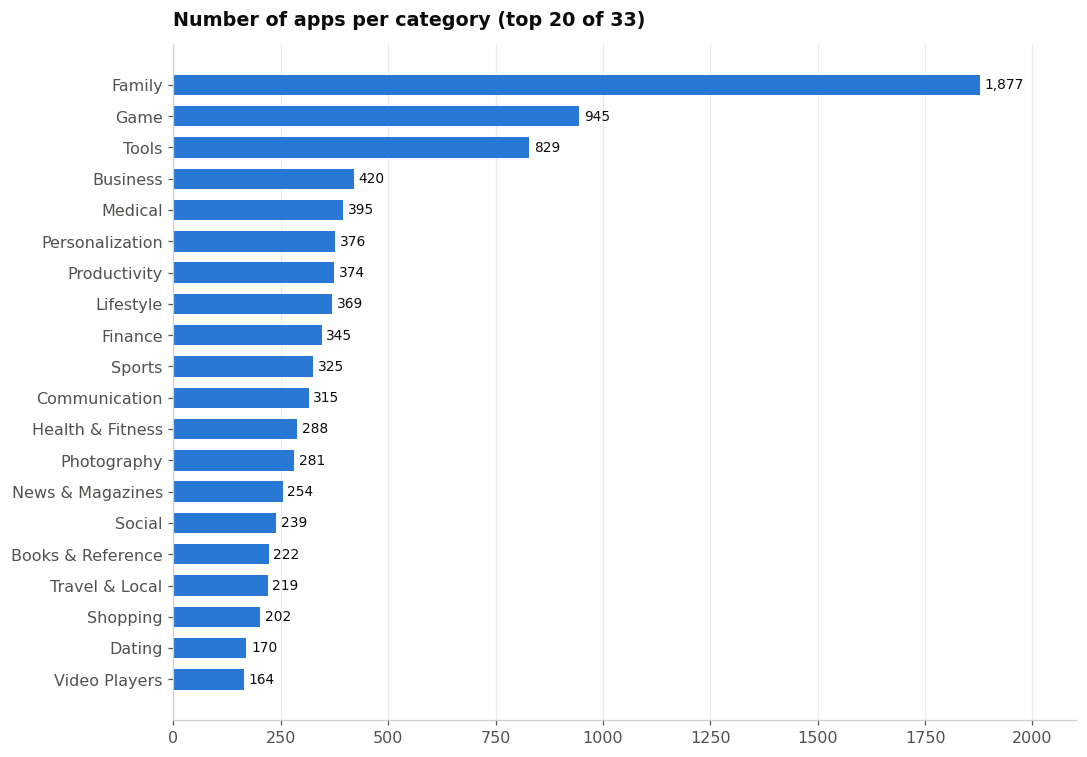

In [11]:
cat = apps.groupby("Category").agg(apps=("App", "size"), median_installs=("Installs", "median"),
                                   total_installs=("Installs", "sum"), avg_rating=("Rating", "mean"))
cat.index = cat.index.map(pretty)
top = cat.sort_values("apps").tail(20)

fig, ax = plt.subplots(figsize=(10, 7))
b = ax.barh(top.index, top["apps"], color=BLUE, height=0.65)
ax.bar_label(b, labels=[f"{v:,}" for v in top["apps"]], padding=3, color=INK, fontsize=9)
ax.set_xlim(0, top["apps"].max() * 1.12)
ax.set_title("Number of apps per category (top 20 of 33)")
ax.grid(axis="y", visible=False)
plt.tight_layout()
plt.savefig("images/apps_per_category.png")
plt.show()

### 3.2 Which categories are the most saturated?
A category is **saturated** when it has **many apps competing for few installs each**. We compare the number of apps with the **median installs per app**:

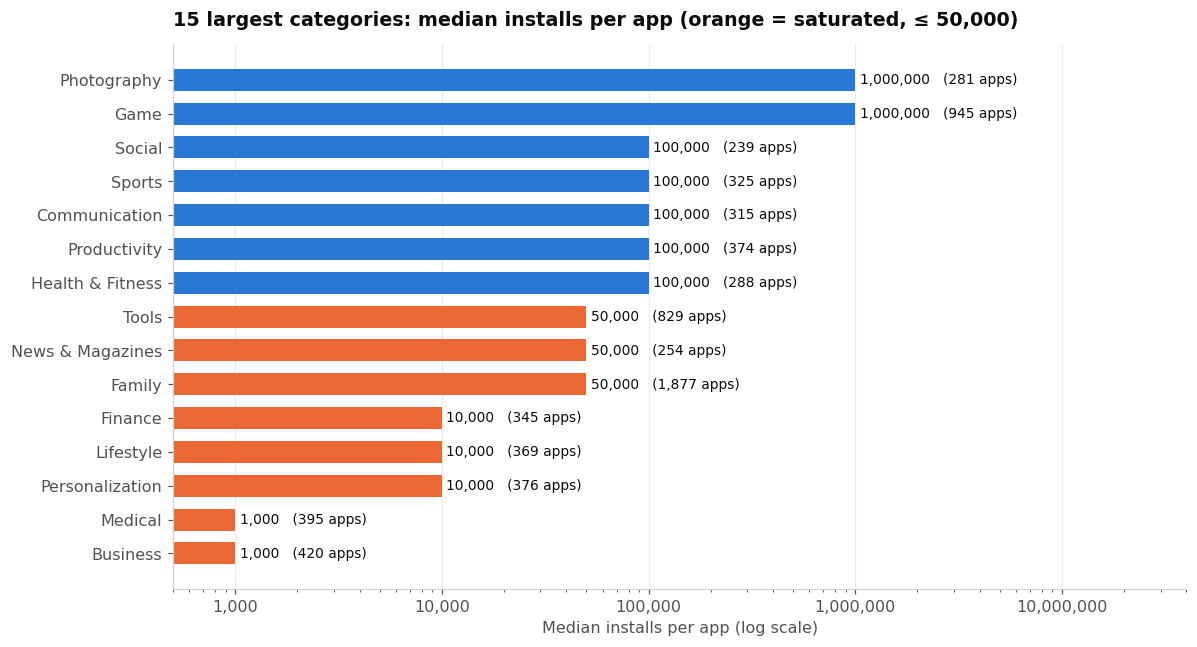

,apps,median_installs,avg_rating
Category,,,
Family,1877,"50,000.00",4.18
Game,945,"1,000,000.00",4.24
Tools,829,"50,000.00",4.04
Business,420,"1,000.00",4.10
Medical,395,"1,000.00",4.17
Personalization,376,"10,000.00",4.33
Productivity,374,"100,000.00",4.18
Lifestyle,369,"10,000.00",4.09


In [12]:
big = cat.sort_values("apps", ascending=False).head(15).sort_values("median_installs")
colors = [ORANGE if v <= 50_000 else BLUE for v in big["median_installs"]]

fig, ax = plt.subplots(figsize=(11, 6))
b = ax.barh(big.index, big["median_installs"], color=colors, height=0.65)
ax.bar_label(b, labels=[f"{m:,.0f}   ({n:,} apps)" for m, n in zip(big["median_installs"], big["apps"])],
             padding=3, color=INK, fontsize=9)
ax.set_xscale("log")
ax.set_xlim(500, big["median_installs"].max() * 40)
ax.xaxis.set_major_formatter(mtick.FuncFormatter(lambda x, _: f"{x:,.0f}"))
ax.set_xlabel("Median installs per app (log scale)")
ax.set_title("15 largest categories: median installs per app (orange = saturated, ≤ 50,000)")
ax.grid(axis="y", visible=False)
plt.tight_layout()
plt.savefig("images/category_saturation.png")
plt.show()

cat.sort_values("apps", ascending=False).head(8)[["apps", "median_installs", "avg_rating"]]

**Observations:**
- **Family (1,877 apps)**, **Game (945)** and **Tools (829)** are by far the largest categories.
- **Family and Tools are the most saturated**: many apps but a median of only **50,000 installs**. **Business** and **Medical** are even harder: ≈ 400 apps each and a median of only **1,000 installs**.
- **Game** is crowded too, but the audience is huge: a median of **1 million installs** per game. Smaller categories such as **Education**, **Entertainment**, **Photography** and **Shopping** also reach a median of 1 million installs — **promising niches** (see the interactive chart in section 9).

## 4. Ratings Analysis

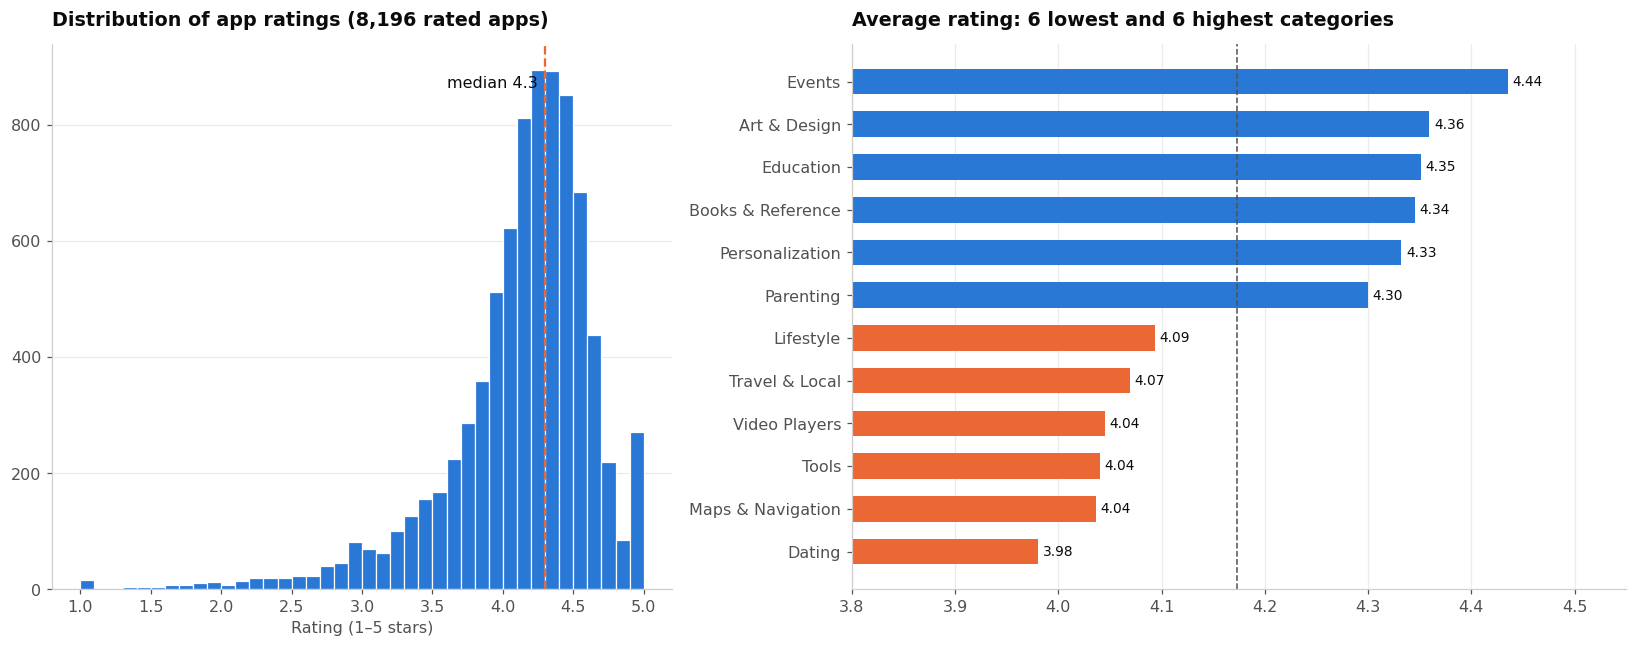

count   8,196.00
mean        4.17
std         0.54
min         1.00
25%         4.00
50%         4.30
75%         4.50
max         5.00
Name: Rating, dtype: float64

In [13]:
rated = apps.dropna(subset=["Rating"])
fig, axes = plt.subplots(1, 2, figsize=(15, 6), gridspec_kw={"width_ratios": [1, 1.25]})

axes[0].hist(rated["Rating"], bins=np.arange(1, 5.1, 0.1), color=BLUE, edgecolor="white", linewidth=0.8)
axes[0].axvline(rated["Rating"].median(), color=ORANGE, ls="--", lw=1.5)
axes[0].text(rated["Rating"].median() - 0.05, axes[0].get_ylim()[1] * 0.92, f"median {rated['Rating'].median():.1f}",
             ha="right", color=INK)
axes[0].set_title(f"Distribution of app ratings ({len(rated):,} rated apps)")
axes[0].set_xlabel("Rating (1–5 stars)")
axes[0].grid(axis="x", visible=False)

r = cat["avg_rating"].sort_values()
r = pd.concat([r.head(6), r.tail(6)])
b = axes[1].barh(r.index, r.values, color=[ORANGE] * 6 + [BLUE] * 6, height=0.6)
axes[1].bar_label(b, labels=[f"{v:.2f}" for v in r.values], padding=3, color=INK, fontsize=9)
axes[1].set_xlim(3.8, 4.55)
axes[1].axvline(rated["Rating"].mean(), color=MUTED, ls="--", lw=1)
axes[1].set_title("Average rating: 6 lowest and 6 highest categories")
axes[1].grid(axis="y", visible=False)
plt.tight_layout()
plt.savefig("images/ratings.png")
plt.show()
rated["Rating"].describe()

**Observations:**
- Ratings are **very high overall**: median **4.3**, and 75 % of apps have **4.0 or more**. A rating below 4 is therefore a bad signal in this market.
- The distribution has a long tail of poorly rated apps (down to 1.0).
- **Events, Art & Design and Education** have the best average ratings (≈ 4.35–4.45); **Dating, Maps & Navigation and Tools** the lowest (≈ 4.0) — categories where users are more demanding or apps less reliable.

## 5. Size and Installs: Is There a Correlation?

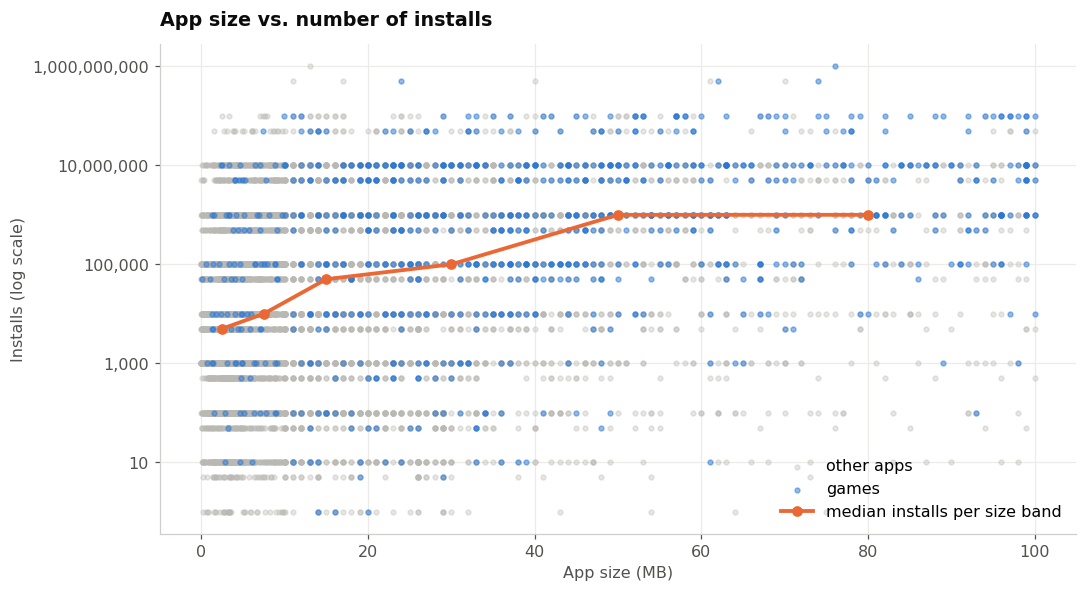

Pearson correlation : 0.13


Spearman correlation: 0.31


In [14]:
sized = apps.dropna(subset=["Size (MB)"])
is_game = sized["Category"] == "GAME"

fig, ax = plt.subplots(figsize=(10, 5.5))
ax.scatter(sized.loc[~is_game, "Size (MB)"], sized.loc[~is_game, "Installs"], s=10, alpha=0.35, color=GREY, label="other apps")
ax.scatter(sized.loc[is_game, "Size (MB)"], sized.loc[is_game, "Installs"], s=10, alpha=0.5, color=BLUE, label="games")
medians = sized.groupby(pd.cut(sized["Size (MB)"], [0, 5, 10, 20, 40, 60, 100]), observed=True)["Installs"].median()
ax.plot([2.5, 7.5, 15, 30, 50, 80], medians.values, color=ORANGE, lw=2.5, marker="o", label="median installs per size band")
ax.set_yscale("log")
ax.yaxis.set_major_formatter(mtick.FuncFormatter(lambda y, _: f"{y:,.0f}"))
ax.set_xlabel("App size (MB)"); ax.set_ylabel("Installs (log scale)")
ax.set_title("App size vs. number of installs")
ax.legend(frameon=False, loc="lower right")
plt.tight_layout()
plt.savefig("images/size_vs_installs.png")
plt.show()

print(f"Pearson correlation : {sized['Size (MB)'].corr(sized['Installs']):.2f}")
print(f"Spearman correlation: {sized['Size (MB)'].corr(sized['Installs'], method='spearman'):.2f}")

**Observations:**
- The **Pearson** correlation is almost zero (0.13) because installs range from 0 to 1 billion; the **Spearman** correlation, based on ranks, shows a **weak positive link (0.31)**.
- The median installs grow with size up to ≈ 50 MB and then stay flat: **larger apps are not penalised** — they are often richer apps (games, social apps) with bigger audiences. Many games (blue) are large *and* popular.
- In other words, **size is not a barrier to adoption**; quality and category matter much more.

## 6. Pricing Analysis

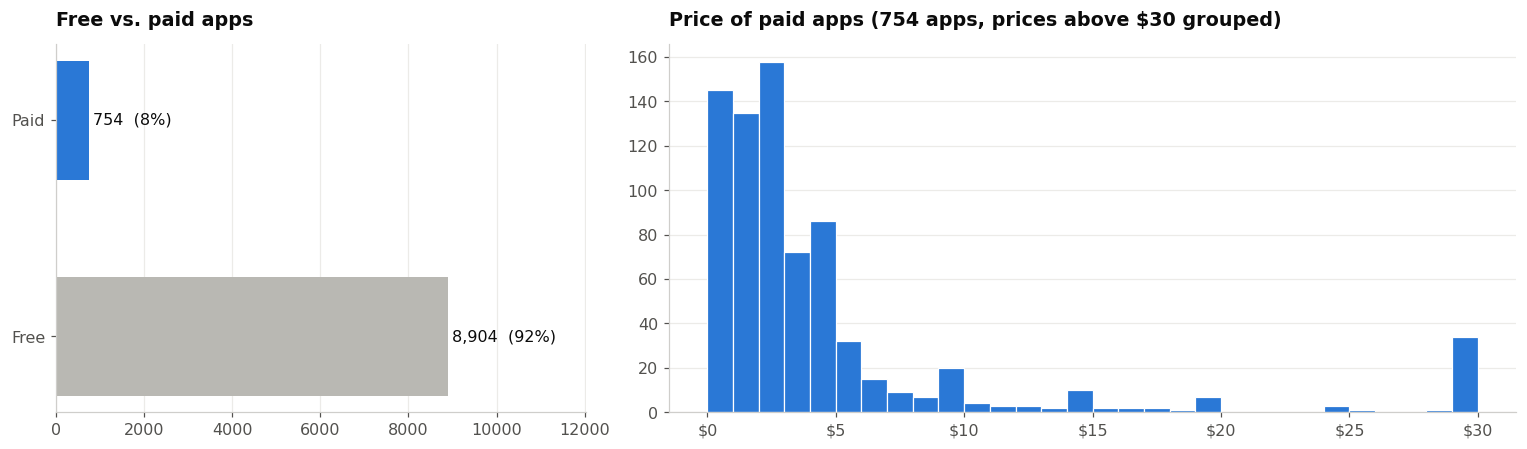

count   754.00
mean     14.06
std      58.82
min       0.99
25%       1.49
50%       2.99
75%       4.99
max     400.00
Name: Price, dtype: float64

In [15]:
paid = apps[apps["Type"] == "Paid"].copy()
fig, axes = plt.subplots(1, 2, figsize=(14, 4.2), gridspec_kw={"width_ratios": [1, 1.6]})

share = apps["Type"].value_counts()
axes[0].barh(share.index, share.values, color=[GREY, BLUE], height=0.55)
for y, v in enumerate(share.values):
    axes[0].text(v + 80, y, f"{v:,}  ({v / share.sum():.0%})", va="center", color=INK)
axes[0].set_xlim(0, share.max() * 1.35)
axes[0].set_title("Free vs. paid apps")
axes[0].grid(axis="y", visible=False)

axes[1].hist(paid["Price"].clip(upper=30), bins=np.arange(0, 31, 1), color=BLUE, edgecolor="white", linewidth=0.8)
axes[1].set_title(f"Price of paid apps ({len(paid)} apps, prices above $30 grouped)")
axes[1].xaxis.set_major_formatter(mtick.FuncFormatter(lambda x, _: f"${x:,.0f}"))
axes[1].grid(axis="x", visible=False)
plt.tight_layout()
plt.savefig("images/pricing.png")
plt.show()
paid["Price"].describe()

**Estimated revenue by category.** A rough lower-bound estimate of the money made from **app purchases** is `price × installs` (it ignores in-app purchases and ads, which is how most free apps earn money).

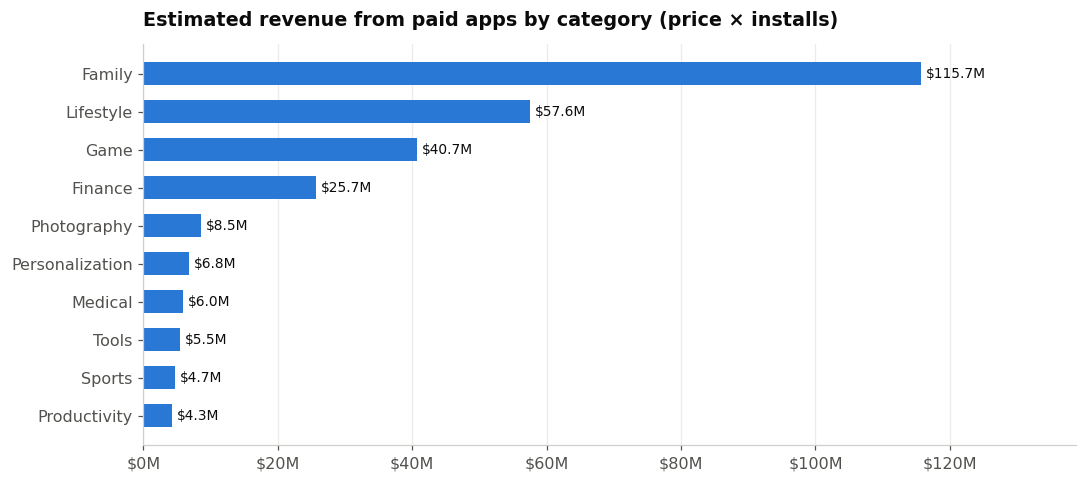

,App,Category,Price,Installs,revenue
172,Minecraft,FAMILY,6.99,10000000,"69,900,000.00"
3986,I am rich,LIFESTYLE,399.99,100000,"39,999,000.00"
4441,I Am Rich Premium,FINANCE,399.99,50000,"19,999,500.00"
660,Hitman Sniper,GAME,0.99,10000000,"9,900,000.00"
730,Grand Theft Auto: San Andreas,GAME,6.99,1000000,"6,990,000.00"
1954,Facetune - For Free,PHOTOGRAPHY,5.99,1000000,"5,990,000.00"


In [16]:
paid["revenue"] = paid["Price"] * paid["Installs"]
rev = paid.groupby("Category")["revenue"].sum().sort_values(ascending=False)
rev.index = rev.index.map(pretty)

fig, ax = plt.subplots(figsize=(10, 4.5))
top_rev = rev.head(10).sort_values()
b = ax.barh(top_rev.index, top_rev.values, color=BLUE, height=0.6)
ax.bar_label(b, labels=[f"${v / 1e6:,.1f}M" for v in top_rev.values], padding=3, color=INK, fontsize=9)
ax.set_xlim(0, top_rev.max() * 1.2)
ax.xaxis.set_major_formatter(mtick.FuncFormatter(lambda x, _: f"${x / 1e6:,.0f}M"))
ax.set_title("Estimated revenue from paid apps by category (price × installs)")
ax.grid(axis="y", visible=False)
plt.tight_layout()
plt.savefig("images/revenue_by_category.png")
plt.show()

paid.sort_values("revenue", ascending=False)[["App", "Category", "Price", "Installs", "revenue"]].head(6)

**Observations:**
- **92 % of apps are free.** Paid apps are cheap: **half cost \$2.99 or less**, and three quarters \$4.99 or less.
- A few absurd prices exist: **23 apps cost more than \$50**, including several "**I am rich**" apps at **\$399.99** that do nothing — a famous Play Store curiosity.
- Revenue from paid apps is **extremely concentrated**: **Minecraft alone (\$6.99 × 10 million installs ≈ \$70M)** represents most of the Family category, and the "I am rich" apps put **Lifestyle in second place**. Outside a few hits, selling the app itself brings little money: **free + in-app purchases or ads is the dominant model**.

## 7. Sentiment Analysis of User Reviews (VADER)
**VADER** (*Valence Aware Dictionary and sEntiment Reasoner*) is a rule-based tool designed for short, informal texts such as social media posts and reviews. It needs no training and understands intensifiers ("very good"), negations ("not good"), punctuation ("good!!!") and emojis. It returns a **compound score** between −1 (very negative) and +1 (very positive), which we turn into 3 classes with the usual thresholds:
- **Positive** if compound ≥ 0.05; **Negative** if compound ≤ −0.05; **Neutral** otherwise.

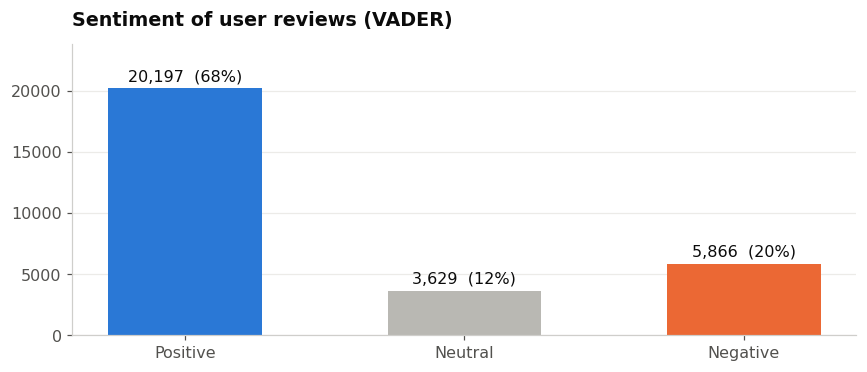

VADER agrees with the sentiment label provided in the dataset for 76% of reviews


In [17]:
sia = SentimentIntensityAnalyzer()
reviews["compound"] = reviews["Translated_Review"].apply(lambda t: sia.polarity_scores(str(t))["compound"])
reviews["vader_sentiment"] = np.select([reviews["compound"] >= 0.05, reviews["compound"] <= -0.05],
                                       ["Positive", "Negative"], default="Neutral")

dist = reviews["vader_sentiment"].value_counts().reindex(["Positive", "Neutral", "Negative"])
fig, ax = plt.subplots(figsize=(8, 3.5))
b = ax.bar(dist.index, dist.values, color=[SENT_COLORS[s] for s in dist.index], width=0.55)
ax.bar_label(b, labels=[f"{v:,}  ({v / dist.sum():.0%})" for v in dist.values], padding=3, color=INK)
ax.set_ylim(0, dist.max() * 1.18)
ax.set_title("Sentiment of user reviews (VADER)")
ax.grid(axis="x", visible=False)
plt.tight_layout()
plt.savefig("images/review_sentiment.png")
plt.show()

agree = (reviews["vader_sentiment"] == reviews["Sentiment"]).mean()
print(f"VADER agrees with the sentiment label provided in the dataset for {agree:.0%} of reviews")

In [18]:
examples = pd.concat([g.sort_values("compound", key=abs, ascending=False).head(2)
                      for _, g in reviews.groupby("vader_sentiment")])
examples[["App", "Translated_Review", "compound", "vader_sentiment"]]

,App,Translated_Review,compound,vader_sentiment
12252,Chrome Dev,"»TOO BRIGHT!… NIGHT MODE, PLEASE. HOW MANY REQ...",-0.99,Negative
7529,"BestCam Selfie-selfie, beauty camera, photo ed...",Bad bad bad bad bad bad bad bad,-0.98,Negative
21385,Firefox Focus: The privacy browser,Nice fast. The purple trashcan button pops eve...,-0.05,Neutral
14890,DEAD TARGET: FPS Zombie Apocalypse Survival Games,Most boring game ever played,-0.05,Neutral
11550,Cat Sim Online: Play with Cats,"Who ever hates game, means lost brains!!! It's...",1.00,Positive
17273,Dude Perfect 2,This game good oun self think good game best g...,1.00,Positive


**Observations:**
- **About two thirds of the reviews are positive**, one in five is negative and about one in ten is neutral.
- VADER agrees with the label provided in the dataset (computed by its author with another tool) for **about three quarters** of the reviews: the two methods mostly disagree on short or neutral texts, where sentiment is ambiguous.
- The examples show VADER's strengths (repeated "bad", capital letters) but also its limits: *"Most boring game ever played"* is only slightly negative (−0.05) because "boring" is a weak word in its dictionary, and a review full of praise can contain negative words. A rule-based tool is a **fast first approximation**, not a perfect judge.

## 8. Sentiment by Category

28,250 reviews matched to a category · 27 categories with at least 300 reviews


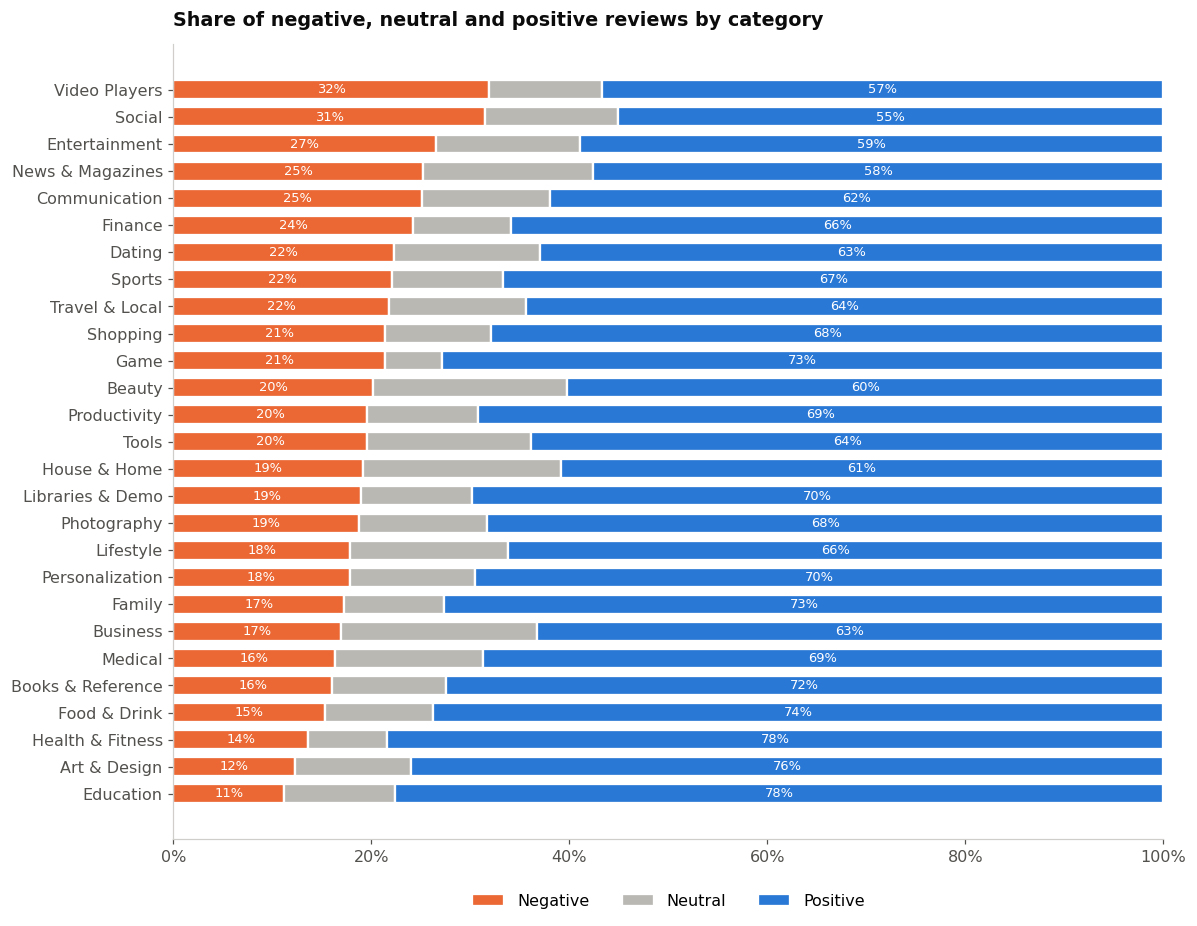

In [19]:
merged = reviews.merge(apps[["App", "Category"]], on="App", how="inner")
by_cat = pd.crosstab(merged["Category"], merged["vader_sentiment"], normalize="index")
by_cat["reviews"] = merged.groupby("Category").size()
by_cat = by_cat[by_cat["reviews"] >= 300].sort_values("Negative")       # enough reviews to be reliable
by_cat.index = by_cat.index.map(pretty)
print(f"{len(merged):,} reviews matched to a category · {len(by_cat)} categories with at least 300 reviews")

fig, ax = plt.subplots(figsize=(11, 8.5))
left = np.zeros(len(by_cat))
for s in ["Negative", "Neutral", "Positive"]:
    ax.barh(by_cat.index, by_cat[s], left=left, color=SENT_COLORS[s], height=0.7, label=s, edgecolor="white", linewidth=1.5)
    for yi, (l, v) in enumerate(zip(left, by_cat[s])):
        if s != "Neutral" and v > 0.08:
            ax.text(l + v / 2, yi, f"{v:.0%}", ha="center", va="center", color="white", fontsize=8.5)
    left += by_cat[s].values
ax.xaxis.set_major_formatter(mtick.PercentFormatter(1))
ax.set_xlim(0, 1)
ax.legend(ncol=3, loc="upper center", bbox_to_anchor=(0.5, -0.05), frameon=False)
ax.set_title("Share of negative, neutral and positive reviews by category")
ax.grid(False)
plt.tight_layout()
plt.savefig("images/sentiment_by_category.png")
plt.show()

**Observations** (categories sorted from the least to the most negative):
- **Most positive:** **Education, Art & Design and Health & Fitness** — only 11–14 % of negative reviews and ≈ 78 % positive.
- **Most negative:** **Video Players and Social** — about **32 % of negative reviews**, followed by **Entertainment (27 %)** and **News & Magazines (25 %)**. These apps are used every day, depend on content, ads and stability, and users quickly complain about bugs, ads or changes.
- **Games** are polarising: 73 % positive but also 21 % negative, with very few neutral reviews — players love or hate a game.

## 9. Interactive Visualisation (plotly)
The chart below combines the main dimensions of the market: **competition** (number of apps), **audience** (median installs), **total installs** (bubble size) and **quality** (average rating, colour). Hover over a bubble to see the details of a category. *(GitHub does not display interactive charts: the same chart is saved as `images/category_map.html` and can be opened in a browser.)*

In [20]:
bubble = cat.reset_index().rename(columns={"index": "Category"})
fig = px.scatter(bubble, x="apps", y="median_installs", size="total_installs", color="avg_rating",
                 hover_name="Category", log_x=True, log_y=True, size_max=55,
                 color_continuous_scale=[[0, "#c9dcf3"], [1, "#0d3f7f"]],
                 labels={"apps": "Number of apps", "median_installs": "Median installs per app",
                         "avg_rating": "Avg rating", "total_installs": "Total installs"},
                 title="Google Play categories: competition, audience and quality")
fig.update_layout(template="simple_white", height=560, title_x=0.01)
fig.write_html("images/category_map.html", include_plotlyjs="cdn")
fig.show()

## 10. Conclusion: 3 Data-Driven Insights for a Developer Launching a New App

**1. Choose a less saturated category with a large audience.**
Family, Tools, Business and Medical are crowded with apps that get few installs (median 1,000–50,000). **Education** stands out: fewer apps, a median of **1 million installs**, the most **positive reviews** and one of the best ratings. Games also have a huge audience but strong competition.

**2. Launch for free and monetise differently.**
**92 % of apps are free** and paid apps rarely sell for more than \$5. Outside a few hits like Minecraft, selling the app brings little: plan for **in-app purchases, subscriptions or ads**. Size is not a barrier — larger, richer apps get as many or more installs.

**3. Quality and stability decide the reviews — especially in daily-use categories.**
The market's standard is high (**median rating 4.3**). In **Video Players and Social**, about **1 review in 3 is negative** (1 in 4 in Entertainment and News): a new app there must be stable, light on ads and listen to user feedback. Monitoring review sentiment (as done here with VADER) is a cheap way to detect problems early.

**Limitations:** data scraped in 2018; installs are lower bounds; reviews cover only 865 apps after cleaning (mostly popular ones); revenue ignores in-app purchases and ads.